# Canal piloto Yaqui -- velocidad superficial por video con STIV, paso a paso

Este notebook es **todo el caso**: parte del video de movil del canal y termina escribiendo
`salidas/velocidad_tiempo_real.mp4`, un video con el formato del caso del rio Bradano
(`casos/06_bradano_stiv`) y dos vistas a color: la camara original y el plano del agua
rectificado, con una flecha por estacion y su velocidad en m/s.

STIV (*Space-Time Image Velocimetry*) programado desde cero sobre OpenCV; pyorc no se usa.

| Paso | Que se hace | Sale |
|---|---|---|
| 0 | parametros y rutas | -- |
| 1 | leer el video | fig1 |
| 2 | geometria: orillas, punto de fuga, rectificacion | fig2 |
| 3 | realce de particulas (top-hat) y estabilizacion | fig3 |
| 4 | una pasada por el video: STI de las 15 estaciones | -- |
| 5 | medida sobre los 81 s y control de calidad | fig4 |
| 6 | la misma medida en ventanas moviles de 12 s | -- |
| 7 | completar la seccion donde no hay trazador | fig5 |
| 8 | escala metrica y velocidades en m/s | fig6 |
| 9 | el video | `velocidad_tiempo_real.mp4`, fig7 |
| 10 | CSV y configuracion | `velocidad_ventanas.csv`, `config.json` |

**Como ejecutarlo**: desde esta carpeta, con el entorno de `requirements_pyorc.txt`,
*Run All*. Tarda unos 7 minutos: ~1.5 min la STI (paso 4) y ~5 min el video (paso 9).

**Lo que hay que saber antes de leer los numeros** (detallado en los pasos 7 y 8):

| dato | origen |
|---|---|
| velocidad en las estaciones 8 a 13 | **medida** por STIV sobre detritos flotantes reales |
| velocidad en las estaciones 1 a 7 | **deducida**: por ahi no pasa ningun trazador; se usa la forma de un perfil Shiono-Knight escalada por lo que miden las de la derecha |
| estaciones 0 y 14 | rechazadas (orilla y medida no fisica); no se rellenan |
| paso a m/s | **supuesto**: ancho de lamina `ANCHO_LAMINA_M` = 5 m, no medido |

El video no muestra estas distinciones; este notebook y `salidas/config.json` si.

> La version anterior de este caso, repartida en siete subcarpetas (medida, arbitro PTV,
> experimentos de alcance y de filtro, modelo de seccion y tres videos), esta en
> `archivo/08_canal_piloto_yaqui/`. Este notebook reune lo que hace falta para llegar al video.

## 0. Parametros y rutas

Todos los valores de juicio estan aqui, marcados `>>> AJUSTABLE <<<`, con el motivo de cada uno.
Ninguno se ha elegido mirando el resultado final: no hay medida de campo con la que compararlo.

In [1]:
import csv
import json
import os
import shutil
import subprocess
import time
import warnings

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import least_squares

RAIZ = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
ARCHIVO_VIDEO = os.path.join(RAIZ, "datos", "canal_riego",
                             "WhatsApp Video 2026-08-16 at 8.07.12 PM.mp4")
DIR_SALIDAS = "salidas"
os.makedirs(DIR_SALIDAS, exist_ok=True)
assert os.path.exists(ARCHIVO_VIDEO), "ejecutar el notebook desde su propia carpeta"

# ffmpeg con libx264, para escribir un mp4 que se vea en el navegador (OpenCV solo trae mp4v)
FFMPEG = os.path.join(RAIZ, "herramientas", "ffmpeg", "ffmpeg.exe")
if not os.path.exists(FFMPEG):
    FFMPEG = shutil.which("ffmpeg") or ""
print("video :", ARCHIVO_VIDEO)
print("ffmpeg:", FFMPEG or "no encontrado (se escribira en mp4v)")

video : C:\Users\sergi\Desktop\medicion_caudal_por_video\datos\canal_riego\WhatsApp Video 2026-08-16 at 8.07.12 PM.mp4
ffmpeg: C:\Users\sergi\Desktop\medicion_caudal_por_video\herramientas\ffmpeg\ffmpeg.exe


In [2]:
# ----------------------------------------------------------------------------------
# >>> AJUSTABLE <<<  Geometria
# ----------------------------------------------------------------------------------
# FOCAL no se puede medir: WhatsApp reencodea y no queda EXIF. 780 px son ~26 mm equivalentes
# sobre 1024 px de ancho, la camara principal tipica de un movil. Es la mayor incertidumbre de
# la geometria: de 700 a 900 px la velocidad cambia +-9 %.
FOCAL = 780.0
# Filas donde se buscan las orillas. Por debajo de 560 empieza la pasarela; por encima de 60 el
# canal ya no se distingue del fondo.
FILA_BORDE_INI, FILA_BORDE_FIN, FILA_BORDE_PASO = 60, 560, 10
# Retranqueo desde cada orilla, en alturas de camara: la franja pegada a la orilla derecha es
# hormigon mojado, no agua. 0.10 es lo minimo que la deja fuera.
RETRANQUEO = 0.10

# ----------------------------------------------------------------------------------
# >>> AJUSTABLE <<<  Realce de particulas
# ----------------------------------------------------------------------------------
# Top-hat de 5 px: mayor que un detrito (2-4 px) y menor que un macrobloque de H.264 (16 px).
TOPHAT_K = 5
SIGMA_PREVIO = 0.8           # desenfoque previo contra el ruido de un pixel del codec

# ----------------------------------------------------------------------------------
# >>> AJUSTABLE <<<  STI
# ----------------------------------------------------------------------------------
# Velocidad esperada (alturas de camara/s). Solo fija el paso de muestreo DS; sale de una
# correlacion de conjunto previa (0.038) redondeada al alza tras ver las estelas.
V_ESPERADA = 0.056
# Tramo medido, en alturas de camara desde la camara. Por debajo de 1.40 esta la sombra de la
# pasarela; por encima de 3.20 el muestreo cae por debajo de ~0.2 px de imagen y la STI se
# aliasea (medido en archivo/08_canal_piloto_yaqui/experimentos/alcance/).
Y_MIN, Y_MAX = 1.40, 3.20
N_ESTACIONES = 15
# Banda de 11 lineas paralelas por estacion, de 0.10 de ancho: con trazador escaso una sola
# linea casi nunca ve una particula. Con 3 lineas la coherencia cae a 0.48-0.75; con 21 no mejora.
BANDA = 0.10
N_LINEAS = 11

# ----------------------------------------------------------------------------------
# >>> AJUSTABLE <<<  Tensor de estructura
# ----------------------------------------------------------------------------------
LADO_BLOQUE = 64
SOLAPE = 0.5
SIGMA_TENSOR = 1.2
# Solo cuentan los bloques mas brillantes: medido, entre el 11 y el 21 % de los bloques de las
# estaciones con trazador contienen una particula, asi que se toma el 15 % superior.
CUANTIL_SENAL = 0.85

# ----------------------------------------------------------------------------------
# >>> AJUSTABLE <<<  Control de calidad
# ----------------------------------------------------------------------------------
COH_MIN = 0.60               # con trazador 0.67-0.85; sin trazador 0.32-0.43
# Densidad de particulas: agua sin trazador < 0.0004, con trazador 0.006-0.020, orilla 0.078
DENSIDAD_MIN = 0.004
DENSIDAD_MAX = 0.05
UMBRAL_PARTICULA = 4.0       # nivel de top-hat que cuenta como particula
V_MAX_FISICA = 3.0 * V_ESPERADA

# ----------------------------------------------------------------------------------
# >>> AJUSTABLE <<<  Ventanas moviles
# ----------------------------------------------------------------------------------
VENTANA = 360                # fotogramas (12 s): menos y las estaciones lentas no acumulan estelas
PASO = 15                    # una ventana nueva cada 0.5 s

# ----------------------------------------------------------------------------------
# >>> AJUSTABLE <<<  Completar la seccion (paso 7)
# ----------------------------------------------------------------------------------
GAMMA_LIMITES = (0.05, 12.0) # rango admitido del parametro de forma de Shiono-Knight
SEMILLA = 20260821           # del temblor por estacion; fija para que el video sea reproducible

# ----------------------------------------------------------------------------------
# >>> AJUSTABLE <<<  Escala metrica SUPUESTA (paso 8)
# ----------------------------------------------------------------------------------
# Ancho de la lamina de agua entre orillas, en metros. NO esta medido. Es la unica cifra que
# pasa de alturas de camara a metros: todas las velocidades en m/s son proporcionales a ella.
ANCHO_LAMINA_M = 5.0

# ----------------------------------------------------------------------------------
# >>> AJUSTABLE <<<  Video (paso 9), formato del video del Bradano
# ----------------------------------------------------------------------------------
ANCHO_LIENZO = 1920
ALTO_PANEL = 630
ALTO_CABECERA, ALTO_PIE, HUECO = 44, 96, 12
ESCALA_RECT = 330.0          # px del panel rectificado por altura de camara
V_COLOR_MAX = 0.20           # m/s, tope de la paleta (el Bradano usa 1.5: alli el agua va 5x mas rapido)
PX_POR_MS = 900              # largo de flecha; el Bradano usa 190 por la misma razon
PCT_REALCE = (0.5, 99.5)     # estirado de contraste, fijo para todo el video
FRAMES_VIDEO = None          # None = todo el video; un numero para una prueba corta

## 1. El video

Video de movil reenviado por WhatsApp: 1024x576, ~30 fps, 81 s y **661 kb/s**. Ese bitrate es
la dificultad del caso: el codificador aplana el agua turbia y lo que queda de textura son
artefactos de bloque fijos a la rejilla de pixeles, que no se mueven con el agua.

La camara esta sobre una pasarela, mirando aguas abajo por el eje del canal, y el agua se aleja
de ella (hacia arriba en la imagen).

1024x576, 29.975 fps, 2429 fotogramas (81.0 s)


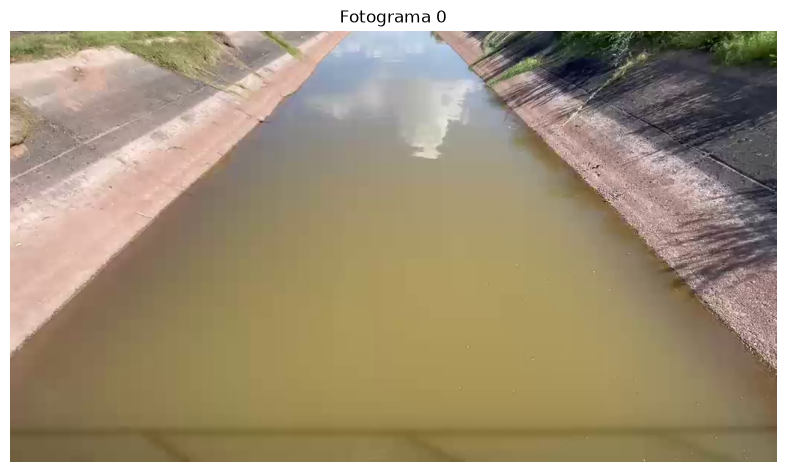

In [3]:
cap = cv2.VideoCapture(ARCHIVO_VIDEO)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
FPS = cap.get(cv2.CAP_PROP_FPS)
ok, f0 = cap.read()
cap.release()
gris0 = cv2.cvtColor(f0, cv2.COLOR_BGR2GRAY)
H_IMG, W_IMG = gris0.shape
print("%dx%d, %.3f fps, %d fotogramas (%.1f s)" % (W_IMG, H_IMG, FPS, N_TOTAL, N_TOTAL / FPS))

plt.figure(figsize=(10, 5.6))
plt.imshow(cv2.cvtColor(f0, cv2.COLOR_BGR2RGB))
plt.title("Fotograma 0")
plt.axis("off")
plt.savefig(os.path.join(DIR_SALIDAS, "fig1_fotograma.png"), dpi=110, bbox_inches="tight")
plt.show()

## 2. Geometria: del fotograma al plano del agua

No hay puntos de control ni ninguna medida, asi que la rectificacion sale **solo de las orillas**:

1. **Orillas.** En cada fila se busca el maximo gradiente horizontal en cada mitad de la imagen,
   y se ajusta una recta `x = a*y + b` a cada orilla con RANSAC (los puntos de vegetacion o de
   reflejos quedan fuera).
2. **Punto de fuga.** Las dos orillas son paralelas en el mundo, asi que se cortan en el punto de
   fuga del eje del canal. Suponiendo **roll nulo**, su fila es el horizonte.
3. **Inclinacion y homografia.** Con la focal supuesta, la altura del horizonte da la inclinacion
   de la camara, y de ahi la homografia suelo -> imagen. La unidad de longitud es la **altura de la
   camara** sobre el agua, que no se conoce: por eso todo sale en "alturas de camara".

Coordenadas de suelo: `X` a traves del canal (0 cerca del eje) e `Y` distancia a la camara a lo
largo del canal. El agua avanza en +Y.

Un aviso: que el ancho del canal salga constante en el plano rectificado **no valida nada**. El
punto de fuga es la interseccion de las dos orillas, asi que la homografia las vuelve paralelas por
construccion. Lo que si valida la geometria es que las estelas de la STI salgan **rectas** (paso 5):
con un horizonte equivocado, una particula a velocidad constante dibujaria una curva.

In [4]:
def _ransac_recta(P, tol=6.0, iters=600):
    # Recta x = a*y + b robusta a puntos sueltos
    rng = np.random.default_rng(0)
    mejor = (0, 0.0, 0.0)
    for _ in range(iters):
        i = rng.choice(len(P), 2, replace=False)
        (x1, y1), (x2, y2) = P[i]
        if abs(y1 - y2) < 20:
            continue
        a = (x1 - x2) / (y1 - y2)
        b = x1 - a * y1
        n = (np.abs(P[:, 0] - (a * P[:, 1] + b)) < tol).sum()
        if n > mejor[0]:
            mejor = (n, a, b)
    _, a, b = mejor
    m = np.abs(P[:, 0] - (a * P[:, 1] + b)) < tol
    A = np.polyfit(P[m, 1], P[m, 0], 1)
    return float(A[0]), float(A[1]), int(m.sum()), int(len(P))


def detectar_orillas(gris):
    # Maximo gradiente horizontal fila a fila, en cada mitad de la imagen
    H, W = gris.shape
    izq, der = [], []
    for y in range(FILA_BORDE_INI, FILA_BORDE_FIN, FILA_BORDE_PASO):
        fila = cv2.GaussianBlur(gris[y:y + 1, :].astype(np.float32), (9, 1), 0).ravel()
        d = np.abs(np.diff(fila))
        izq.append((int(np.argmax(d[:W // 2])), y))
        der.append((int(W // 2 + np.argmax(d[W // 2:])), y))
    return _ransac_recta(np.array(izq, float)), _ransac_recta(np.array(der, float))


class Geometria:
    # Rectificacion del plano del agua por el punto de fuga; camara a altura 1

    def __init__(self, gris, focal=FOCAL):
        H, W = gris.shape
        self.W, self.H = W, H
        (self.al, self.bl, ni, nt), (self.ar, self.br, ni2, nt2) = detectar_orillas(gris)
        self.inliers = (ni, nt, ni2, nt2)
        self.yv = (self.br - self.bl) / (self.al - self.ar)
        self.xv = self.al * self.yv + self.bl
        self.focal = focal
        cx, cy = W / 2.0, H / 2.0
        self.inclinacion = np.arctan2(cy - self.yv, focal)
        K = np.array([[focal, 0, cx], [0, focal, cy], [0, 0, 1]])
        s, c = np.sin(self.inclinacion), np.cos(self.inclinacion)
        self.Hgi = K @ np.array([[1, 0, 0], [0, -s, c], [0, c, s]])   # suelo -> imagen
        self.Hig = np.linalg.inv(self.Hgi)                                # imagen -> suelo
        ys = np.linspace(FILA_BORDE_INI + 60, FILA_BORDE_FIN - 40, 9)
        Gl = self.a_suelo(np.column_stack([self.al * ys + self.bl, ys]))
        Gr = self.a_suelo(np.column_stack([self.ar * ys + self.br, ys]))
        self.ancho = float(np.mean(Gr[:, 0] - Gl[:, 0]))
        self.X_izq = float(np.mean(Gl[:, 0]))
        self.X_der = float(np.mean(Gr[:, 0]))

    def a_imagen(self, P):
        P = np.atleast_2d(np.asarray(P, float))
        q = np.column_stack([P, np.ones(len(P))]) @ self.Hgi.T
        return q[:, :2] / q[:, 2:]

    def a_suelo(self, P):
        P = np.atleast_2d(np.asarray(P, float))
        q = np.column_stack([P, np.ones(len(P))]) @ self.Hig.T
        return q[:, :2] / q[:, 2:]

    def poligono_agua(self):
        ys = np.array([0.0, float(self.H)])
        xl, xr = self.al * ys + self.bl, self.ar * ys + self.br
        return np.array([[xl[0], ys[0]], [xr[0], ys[0]], [xr[1], ys[1]], [xl[1], ys[1]]],
                        np.int32)

    def estaciones(self):
        return np.linspace(self.X_izq + RETRANQUEO, self.X_der - RETRANQUEO, N_ESTACIONES)

    def mapa_rect(self, rst):
        # Coordenadas de imagen de cada pixel del lienzo rectificado (fila 0 = lo mas lejano)
        GX, GY = np.meshgrid(np.linspace(rst["X0"], rst["X1"], rst["w"]),
                             np.linspace(rst["Y1"], rst["Y0"], rst["h"]))
        I = self.a_imagen(np.column_stack([GX.ravel(), GY.ravel()]))
        return I.reshape(rst["h"], rst["w"], 2).astype(np.float32)

    def rect_a_pix(self, rst, P):
        P = np.atleast_2d(np.asarray(P, float))
        x = (P[:, 0] - rst["X0"]) / (rst["X1"] - rst["X0"]) * (rst["w"] - 1)
        y = (rst["Y1"] - P[:, 1]) / (rst["Y1"] - rst["Y0"]) * (rst["h"] - 1)
        return np.column_stack([x, y])


geo = Geometria(gris0)
Xs = geo.estaciones()
print("orilla izq  x = %+.4f*y %+.2f  (%d/%d inliers)" % (geo.al, geo.bl, *geo.inliers[:2]))
print("orilla der  x = %+.4f*y %+.2f  (%d/%d inliers)" % (geo.ar, geo.br, *geo.inliers[2:]))
print("punto de fuga (%.1f, %.1f)   inclinacion %.2f grados" % (geo.xv, geo.yv,
                                                               np.degrees(geo.inclinacion)))
print("ancho del canal %.4f alturas de camara, de X = %.3f a %.3f" % (geo.ancho, geo.X_izq,
                                                                    geo.X_der))
print("estaciones en X =", np.round(Xs, 3))

orilla izq  x = -1.0745*y +461.90  (35/50 inliers)
orilla der  x = +0.9874*y +571.39  (18/50 inliers)
punto de fuga (519.0, -53.1)   inclinacion 23.62 grados
ancho del canal 2.2505 alturas de camara, de X = -1.149 a 1.101
estaciones en X = [-1.049 -0.903 -0.756 -0.61  -0.463 -0.317 -0.171 -0.024  0.122  0.269
  0.415  0.562  0.708  0.855  1.001]


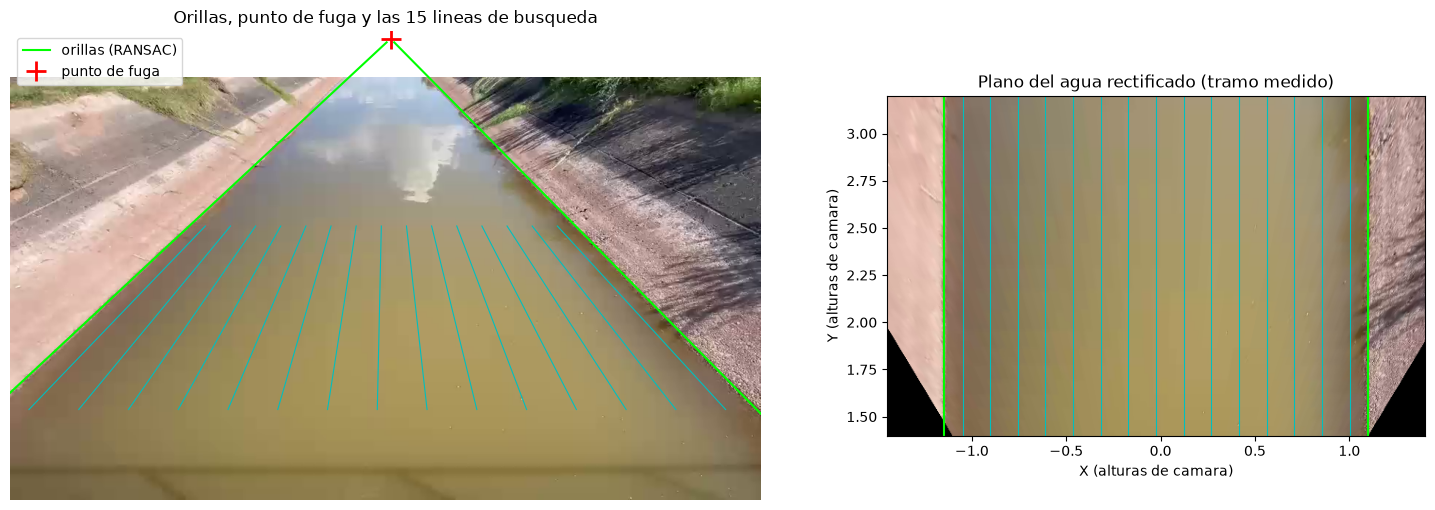

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax[0].imshow(cv2.cvtColor(f0, cv2.COLOR_BGR2RGB))
ys = np.array([geo.yv + 5, H_IMG])
ax[0].plot(geo.al * ys + geo.bl, ys, "lime", lw=1.5, label="orillas (RANSAC)")
ax[0].plot(geo.ar * ys + geo.br, ys, "lime", lw=1.5)
ax[0].plot(geo.xv, geo.yv, "r+", ms=14, mew=2, label="punto de fuga")
for X in Xs:
    q = geo.a_imagen(np.column_stack([np.full(20, X), np.linspace(Y_MIN, Y_MAX, 20)]))
    ax[0].plot(q[:, 0], q[:, 1], "c", lw=0.8)
ax[0].set_xlim(0, W_IMG); ax[0].set_ylim(H_IMG, min(geo.yv, 0) - 10)
ax[0].legend(loc="upper left"); ax[0].set_title("Orillas, punto de fuga y las 15 lineas de busqueda")
ax[0].axis("off")

rst_fig = dict(X0=geo.X_izq - 0.3, X1=geo.X_der + 0.3, Y0=Y_MIN, Y1=Y_MAX, escala=200.0)
rst_fig["w"] = int((rst_fig["X1"] - rst_fig["X0"]) * 200); rst_fig["h"] = int((Y_MAX - Y_MIN) * 200)
m = geo.mapa_rect(rst_fig)
rect0 = cv2.remap(f0, m[..., 0], m[..., 1], cv2.INTER_LINEAR)
ax[1].imshow(cv2.cvtColor(rect0, cv2.COLOR_BGR2RGB),
             extent=(rst_fig["X0"], rst_fig["X1"], Y_MIN, Y_MAX))
for X in Xs:
    ax[1].axvline(X, color="c", lw=0.8)
ax[1].axvline(geo.X_izq, color="lime"); ax[1].axvline(geo.X_der, color="lime")
ax[1].set_xlabel("X (alturas de camara)"); ax[1].set_ylabel("Y (alturas de camara)")
ax[1].set_title("Plano del agua rectificado (tramo medido)")
plt.tight_layout()
plt.savefig(os.path.join(DIR_SALIDAS, "fig2_geometria.png"), dpi=110, bbox_inches="tight")
plt.show()

## 3. Realce de particulas y estabilizacion

**Top-hat morfologico.** Lo unico que se mueve con el agua de forma reconocible son detritos
vegetales pequenos y brillantes que caen de la orilla derecha. El top-hat (imagen menos su apertura
con un disco de 5 px) deja solo lo que es mas brillante que su entorno inmediato y mas pequeno que
el disco: los detritos sobreviven y los macrobloques del codec, que son regiones planas, desaparecen.
Es lo que convierte este video en medible.

**Estabilizacion.** El movil esta a pulso y se desplaza ~7 px de mediana a lo largo del video.
Se siguen ~600 esquinas de las orillas (fuera del agua) con Lucas-Kanade **siempre contra el
fotograma 0**, no en cadena, para que el error no se acumule, y se ajusta una afinidad por fotograma.
Todas las coordenadas del fotograma 0 se llevan al fotograma actual con esa afinidad.

600 puntos de anclaje para estabilizar


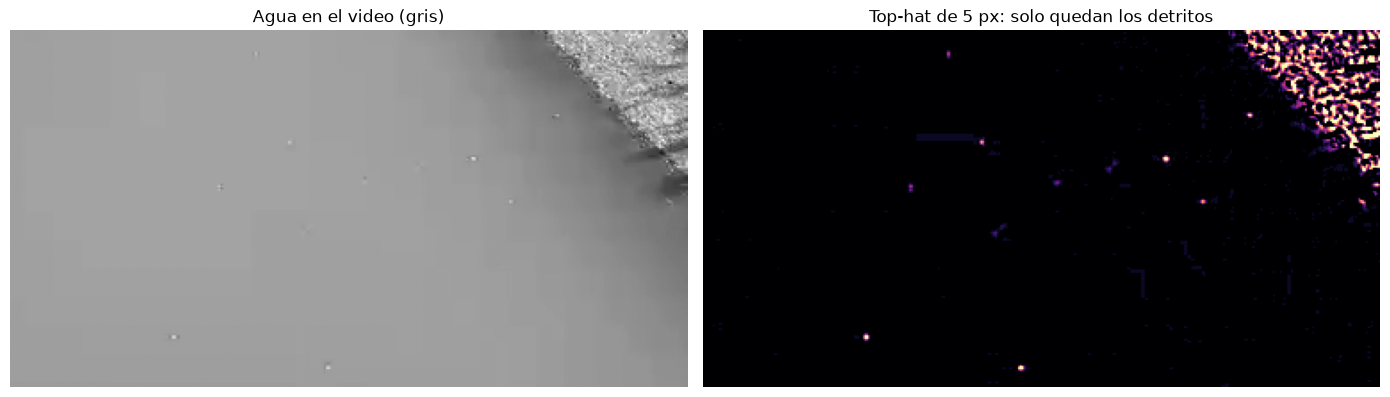

In [6]:
def realzar(gris):
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TOPHAT_K, TOPHAT_K))
    suave = cv2.GaussianBlur(gris, (0, 0), SIGMA_PREVIO)
    return cv2.morphologyEx(suave, cv2.MORPH_TOPHAT, se).astype(np.float32)


def estimar_estabilizacion(gris0, gris, p0):
    # Afinidad fotograma 0 -> fotograma actual
    p1, st, _ = cv2.calcOpticalFlowPyrLK(
        gris0, gris, p0, None, winSize=(21, 21), maxLevel=3,
        criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
    ok = st.ravel() == 1
    if ok.sum() < 20:
        return np.array([[1.0, 0, 0], [0, 1.0, 0]]), 0.0
    A, _ = cv2.estimateAffinePartial2D(p0[ok], p1[ok], method=cv2.RANSAC,
                                       ransacReprojThreshold=2.0)
    if A is None:
        return np.array([[1.0, 0, 0], [0, 1.0, 0]]), 0.0
    d = float(np.median(np.linalg.norm((p1[ok] - p0[ok]).reshape(-1, 2), axis=1)))
    return A, d


# Puntos de anclaje: esquinas fuera del agua y por encima de la pasarela
mascara = np.zeros(gris0.shape, np.uint8)
mascara[0:FILA_BORDE_FIN - 40, :] = 255
cv2.fillPoly(mascara, [geo.poligono_agua()], 0)
p0 = cv2.goodFeaturesToTrack(gris0, 600, 0.01, 7, mask=mascara)
print("%d puntos de anclaje para estabilizar" % len(p0))

th0 = realzar(gris0)
y0_, y1_, x0_, x1_ = 250, 450, 520, 900
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(gris0[y0_:y1_, x0_:x1_], cmap="gray"); ax[0].set_title("Agua en el video (gris)")
ax[1].imshow(th0[y0_:y1_, x0_:x1_], cmap="magma", vmax=15)
ax[1].set_title("Top-hat de 5 px: solo quedan los detritos")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(DIR_SALIDAS, "fig3_realce.png"), dpi=110, bbox_inches="tight")
plt.show()

## 4. Una sola pasada por el video: la STI de cada estacion

Una **STI** (imagen espacio-tiempo) apila, fotograma tras fotograma, el brillo a lo largo de una
linea paralela al flujo. Una particula que avanza a velocidad constante deja en ella una **estela
recta** cuya pendiente es la velocidad: `v = pendiente x DS x fps`.

- Las lineas se definen en el **plano rectificado** (X fijo, Y de 1.40 a 3.20) con paso
  `DS = V_ESPERADA / fps`, y se proyectan a la imagen con la homografia y la afinidad del fotograma.
  Asi el paso es constante en el suelo aunque en la imagen las lineas converjan.
- En cada estacion hay una **banda de 11 lineas** paralelas y la STI es su media.
- Se guarda tambien, por estacion y fotograma, cuantas posiciones tienen una particula
  (top-hat > `UMBRAL_PARTICULA` en alguna linea de la banda): es la **densidad de trazador**,
  el criterio de calidad decisivo en este video.
- Y se guarda la afinidad de cada fotograma, que reutiliza el video del paso 9.

In [7]:
DS = V_ESPERADA / FPS
N_MUES = int((Y_MAX - Y_MIN) / DS)
Yv = Y_MIN + DS * np.arange(N_MUES)
offs = np.linspace(-BANDA / 2, BANDA / 2, N_LINEAS)
mapas = np.empty((N_ESTACIONES, N_LINEAS, N_MUES, 2), np.float32)
for a, X in enumerate(Xs):
    for b, o in enumerate(offs):
        mapas[a, b] = geo.a_imagen(np.column_stack([np.full(N_MUES, X + o), Yv]))
pts = mapas.reshape(-1, 2)
nr = N_ESTACIONES * N_LINEAS

sti = np.zeros((N_ESTACIONES, N_TOTAL, N_MUES), np.float32)
cuenta = np.zeros((N_ESTACIONES, N_TOTAL), np.int32)
afines = np.zeros((N_TOTAL, 2, 3), np.float32)
derivas = []
cap = cv2.VideoCapture(ARCHIVO_VIDEO)
t0 = time.time()
NF = 0
for i in range(N_TOTAL):
    ok, f = cap.read()
    if not ok:
        break
    g = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
    A, d = estimar_estabilizacion(gris0, g, p0)
    afines[i] = A
    derivas.append(d)
    xy = pts @ A[:, :2].T + A[:, 2]
    v = cv2.remap(realzar(g), xy[:, 0].reshape(nr, N_MUES).astype(np.float32),
                  xy[:, 1].reshape(nr, N_MUES).astype(np.float32), cv2.INTER_LINEAR)
    v = v.reshape(N_ESTACIONES, N_LINEAS, N_MUES)
    sti[:, i, :] = v.mean(axis=1)
    cuenta[:, i] = (v.max(axis=1) > UMBRAL_PARTICULA).sum(axis=1)
    NF = i + 1
    if NF % 500 == 0:
        print("  %d/%d fotogramas (%.0f s)" % (NF, N_TOTAL, time.time() - t0))
cap.release()
sti, cuenta, afines = sti[:, :NF], cuenta[:, :NF], afines[:NF]
print("STI: %d estaciones x %d fotogramas x %d muestras, DS = %.5f, en %.0f s"
      % (N_ESTACIONES, NF, N_MUES, DS, time.time() - t0))
print("deriva de la camara: mediana %.2f px, maxima %.2f px" % (np.median(derivas),
                                                              np.max(derivas)))

  500/2429 fotogramas (7 s)


  1000/2429 fotogramas (13 s)


  1500/2429 fotogramas (19 s)


  2000/2429 fotogramas (27 s)


STI: 15 estaciones x 2429 fotogramas x 963 muestras, DS = 0.00187, en 35 s
deriva de la camara: mediana 6.70 px, maxima 10.08 px


## 5. Medida sobre los 81 s y control de calidad

**Tensor de estructura con seleccion por senal.** La STI se trocea en bloques de 64x64 con solape;
en cada uno el tensor de estructura da la orientacion dominante y su coherencia (0 = sin direccion,
1 = estela perfecta). La pendiente de la estacion es la mediana de las orientaciones ponderada por
coherencia, **pero solo sobre el 15 % de bloques mas brillantes**. Sin esa seleccion gana el residuo
estatico (estelas verticales = velocidad cero, perfectamente coherentes) y todas las estaciones dan 0.

**Control de calidad**, con criterios independientes:

| criterio | rechaza |
|---|---|
| densidad < `DENSIDAD_MIN` | agua sin trazador: no hay nada que medir |
| densidad > `DENSIDAD_MAX` | orilla: hormigon mojado, no agua |
| coherencia < `COH_MIN` | STI sin estelas claras |
| v > `V_MAX_FISICA` o v <= 0 | medida no fisica o en sentido contrario |

In [8]:
def tensor_seleccion(im, blk=LADO_BLOQUE, cuantil=CUANTIL_SENAL, sigma=SIGMA_TENSOR,
                     solape=SOLAPE):
    # Pendiente dominante (muestras/fotograma) y coherencia, solo con los bloques con particula
    im = np.ascontiguousarray(im, dtype=np.float32)
    g = cv2.GaussianBlur(im, (0, 0), sigma)
    gt, gs = np.gradient(g)
    K = (blk, blk)
    Jss = cv2.boxFilter(gs * gs, -1, K, normalize=False)
    Jtt = cv2.boxFilter(gt * gt, -1, K, normalize=False)
    Jst = cv2.boxFilter(gs * gt, -1, K, normalize=False)
    Emax = cv2.dilate(im, np.ones((blk, blk), np.uint8))
    h, w = im.shape
    stp = max(1, int(blk * (1 - solape)))
    r = np.arange(blk // 2, h - blk // 2, stp)
    c = np.arange(blk // 2, w - blk // 2, stp)
    if len(r) < 2 or len(c) < 2:
        return np.nan, 0.0
    R, C = np.meshgrid(r, c, indexing="ij")
    jss, jtt, jst, e = Jss[R, C], Jtt[R, C], Jst[R, C], Emax[R, C]
    tr = jss + jtt
    ok = tr > 1e-12
    ang = 0.5 * np.arctan2(2 * jst, jss - jtt)
    coh = np.where(ok, np.hypot(jss - jtt, 2 * jst) / np.maximum(tr, 1e-12), 0.0)
    ang, coh, e = ang[ok], coh[ok], e[ok]
    if ang.size < 8:
        return np.nan, 0.0
    m = e >= np.quantile(e, cuantil)
    if m.sum() < 5:
        return np.nan, 0.0
    a, cc = ang[m], coh[m]
    o = np.argsort(a)
    a, cc = a[o], cc[o]
    cw = np.cumsum(cc)
    med = a[np.searchsorted(cw, cw[-1] / 2)]
    return float(-np.tan(med)), float(np.median(cc))


def motivos_rechazo(dens, v, coh):
    motivos = []
    if dens < DENSIDAD_MIN:
        motivos.append("sin_trazador")
    if dens > DENSIDAD_MAX:
        motivos.append("orilla")
    if not np.isfinite(v):
        motivos.append("sin_tensor")
    else:
        if coh < COH_MIN:
            motivos.append("coherencia")
        if abs(v) > V_MAX_FISICA:
            motivos.append("v_no_fisica")
        if v <= 0:
            motivos.append("sentido")
    return motivos


sti_total = sti - sti.mean(axis=1, keepdims=True)   # quita el fondo estatico de cada posicion
medida_total = []
print(" est     X     densidad  coher.   v (alt.cam/s)  estado")
for a in range(N_ESTACIONES):
    dens = cuenta[a].sum() / float(NF * N_MUES)
    pend, coh = tensor_seleccion(sti_total[a])
    v = pend * DS * FPS if np.isfinite(pend) else np.nan
    mot = motivos_rechazo(dens, v, coh)
    medida_total.append(dict(estacion=a, X=float(Xs[a]), densidad=dens, coherencia=coh,
                             v=v, motivos=mot))
    print(" %2d  %+.3f   %.5f   %.3f   %+.4f        %s"
          % (a, Xs[a], dens, coh, v, "OK" if not mot else ";".join(mot)))
acept = [m for m in medida_total if not m["motivos"]]
print("\n%d de %d estaciones aceptadas, v mediana %.4f alturas de camara/s"
      % (len(acept), N_ESTACIONES, np.median([m["v"] for m in acept])))

 est     X     densidad  coher.   v (alt.cam/s)  estado
  0  -1.049   0.01023   0.580   +0.7551        coherencia;v_no_fisica


  1  -0.903   0.00039   0.527   +0.0225        sin_trazador;coherencia


  2  -0.756   0.00001   0.318   +0.0002        sin_trazador;coherencia
  3  -0.610   0.00003   0.405   +0.0003        sin_trazador;coherencia


  4  -0.463   0.00002   0.359   +0.0010        sin_trazador;coherencia


  5  -0.317   0.00002   0.383   +0.0004        sin_trazador;coherencia
  6  -0.171   0.00001   0.351   +0.0060        sin_trazador;coherencia


  7  -0.024   0.00018   0.394   -0.0022        sin_trazador;coherencia;sentido


  8  +0.122   0.00633   0.707   +0.0585        OK
  9  +0.269   0.00575   0.656   +0.0635        OK


 10  +0.415   0.01042   0.820   +0.0646        OK
 11  +0.562   0.01356   0.797   +0.0594        OK


 12  +0.708   0.01496   0.729   +0.0431        OK


 13  +0.855   0.01969   0.698   +0.0279        OK
 14  +1.001   0.07779   0.674   +0.0185        orilla

6 de 15 estaciones aceptadas, v mediana 0.0590 alturas de camara/s


Las estaciones aceptadas son las del tercio derecho, por donde viajan los detritos. Las de la
izquierda tienen 15 veces menos particulas: **no se pueden medir**, y no es un fallo del metodo
sino que ahi el video no contiene nada que se mueva con el agua.

La figura compara la STI de una estacion aceptada (estelas rectas inclinadas: la pendiente es la
velocidad) con una de la mitad izquierda (sin estelas).

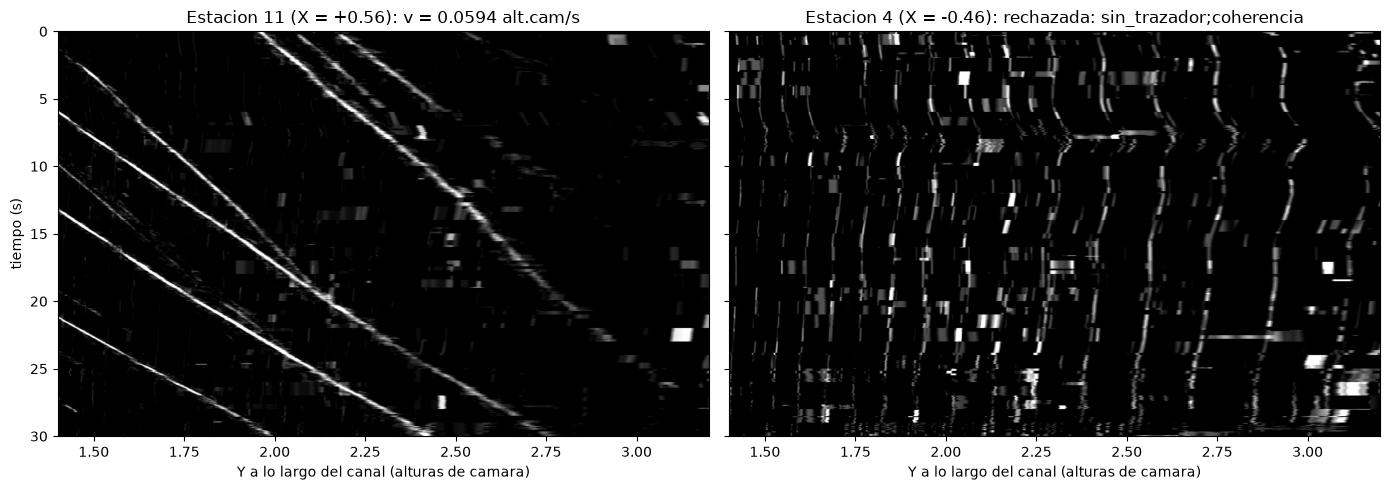

In [9]:
a_ok = acept[len(acept) // 2]["estacion"]
a_no = 4
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for k, a in enumerate((a_ok, a_no)):
    im = sti_total[a, :900]
    ax[k].imshow(im, cmap="gray", aspect="auto", vmin=0, vmax=np.percentile(im, 99.5),
                 extent=(Y_MIN, Y_MAX, 900 / FPS, 0))
    ax[k].set_xlabel("Y a lo largo del canal (alturas de camara)")
    m = medida_total[a]
    ax[k].set_title("Estacion %d (X = %+.2f): %s" % (a, m["X"], "v = %.4f alt.cam/s" % m["v"]
                    if not m["motivos"] else "rechazada: " + ";".join(m["motivos"])))
ax[0].set_ylabel("tiempo (s)")
plt.tight_layout()
plt.savefig(os.path.join(DIR_SALIDAS, "fig4_sti.png"), dpi=110, bbox_inches="tight")
plt.show()

## 6. La misma medida en ventanas moviles

El video muestra la velocidad cambiando en el tiempo, asi que se repite la medida en ventanas de
`VENTANA` fotogramas (12 s) que avanzan `PASO` fotogramas (0.5 s): 138 ventanas. En cada una se
resta la media temporal **de esa ventana** y se aplican el mismo tensor y el mismo control de calidad.

Si la mediana de las ventanas coincide con la medida sobre los 81 s, el numero no depende de una
ventana afortunada.

In [10]:
centros, res = [], []
for w0 in range(0, max(1, NF - VENTANA + 1), PASO):
    w1 = w0 + VENTANA
    centros.append((w0 + w1) // 2)
    fila = []
    for a in range(N_ESTACIONES):
        im = sti[a, w0:w1]
        im = im - im.mean(axis=0, keepdims=True)
        dens = float(cuenta[a, w0:w1].sum()) / (VENTANA * N_MUES)
        pend, coh = tensor_seleccion(im)
        v = pend * DS * FPS if np.isfinite(pend) else np.nan
        fila.append((v, coh, dens, not motivos_rechazo(dens, v, coh)))
    res.append(fila)
centros = np.array(centros)
NK = len(centros)

V_med = np.full((NK, N_ESTACIONES), np.nan)        # solo lo que se mide de verdad
for k in range(NK):
    for a in range(N_ESTACIONES):
        if res[k][a][3]:
            V_med[k, a] = res[k][a][0]
mide = np.isfinite(V_med)
med_vent = np.nanmedian(V_med, axis=1)
print("%d ventanas; %d de %d parejas estacion-ventana aceptadas"
      % (NK, mide.sum(), mide.size))
print("estaciones con alguna medida:", np.where(mide.any(axis=0))[0].tolist())
print("mediana de las ventanas %.4f (q05-q95 %.4f - %.4f) frente a %.4f sobre los 81 s"
      % (np.nanmedian(med_vent), np.nanquantile(med_vent, 0.05), np.nanquantile(med_vent, 0.95),
         np.median([m["v"] for m in acept])))

138 ventanas; 589 de 2070 parejas estacion-ventana aceptadas
estaciones con alguna medida: [8, 9, 10, 11, 12, 13]
mediana de las ventanas 0.0598 (q05-q95 0.0432 - 0.0805) frente a 0.0590 sobre los 81 s


## 7. Completar la seccion donde no hay trazador

Hasta aqui todo es medida. Para dibujar el canal de orilla a orilla hay que **deducir** la velocidad
en las estaciones donde no pasa ningun detrito. La regla:

- **Se completan solo las estaciones cuyo rechazo es por falta de trazador** (`sin_trazador` en el
  paso 5): son agua, simplemente agua sin nada que seguir.
- Las rechazadas por otro motivo (la 0, medida no fisica pegada a la orilla izquierda; la 14,
  orilla) **siguen rechazadas** y en el video salen con cuadro rojo, como en el Bradano.

**La forma** del perfil transversal es la de Shiono-Knight para un canal prismatico:
`U(X) = Umax * sqrt((1 - cosh(g*(X - eje)) / cosh(g*W)) / (1 - 1/cosh(g*W)))`, con la pared en las
orillas detectadas (`W` = semiancho) y el eje en el centro geometrico. Solo se ajusta la forma
(`Gamma`) contra las estaciones aceptadas del paso 5. Con datos en un solo lado, el ajuste se va al
limite inferior de `Gamma`, que es la elipse `sqrt(1 - (X/W)^2)`: simetrica por construccion.

**La amplitud sale de la medida, ventana a ventana**: en cada ventana un unico factor de escala
(la mediana de `v_medida / forma(X)` sobre las estaciones que miden) se aplica a toda la seccion.
Cuando el agua acelera, acelera entera.

**Temblor por estacion.** Sin el, las flechas deducidas se moverian en bloque perfecto. Se anade un
ruido cuyos parametros se **miden** sobre los residuos de las estaciones medidas: se separa el desvio
persistente de cada estacion (error de forma del modelo, que no es ruido) del bamboleo temporal, y
solo este se simula, con su desviacion, su autocorrelacion en el tiempo y recortado a sus
percentiles 5-95.

In [11]:
# Las estaciones que nunca miden dan columnas vacias en nanmean/nanmedian: es lo esperado
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")


def skm(X, eje, Gamma, Umax, W):
    # Perfil Shiono-Knight con pared en eje +- W
    X = np.atleast_1d(np.asarray(X, float))
    g = Gamma / W
    chW = np.cosh(np.clip(g * W, 0, 60))
    ch = np.cosh(np.clip(g * (X - eje), -60, 60))
    Wn = (1.0 - ch / chW) / max(1.0 - 1.0 / chW, 1e-12)
    u = Umax * np.sqrt(np.maximum(Wn, 0.0))
    u[np.abs(X - eje) > W] = 0.0
    return u


EJE = 0.5 * (geo.X_izq + geo.X_der)
SEMI = 0.5 * geo.ancho
Xa = np.array([m["X"] for m in acept]); Ua = np.array([m["v"] for m in acept])
aj = least_squares(lambda p: skm(Xa, EJE, p[0], p[1], SEMI) - Ua, [1.0, Ua.max()],
                   bounds=([GAMMA_LIMITES[0], 0], [GAMMA_LIMITES[1], 1.0]))
GAMMA, UMAX = aj.x
forma = skm(Xs, EJE, GAMMA, 1.0, SEMI)
forma = np.maximum(forma, 1e-6) / forma.max()
print("Shiono-Knight: Gamma = %.3f%s, rms %.4f alt.cam/s sobre %d estaciones"
      % (GAMMA, " (en el limite inferior)" if GAMMA <= GAMMA_LIMITES[0] * 1.001 else "",
         np.sqrt(np.mean(aj.fun ** 2)), len(Xa)))

# Que estaciones se completan y cuales quedan rechazadas
rellenar = np.array(["sin_trazador" in m["motivos"] for m in medida_total])
sobre_agua = mide.any(axis=0) | rellenar
print("se completan:", np.where(rellenar)[0].tolist(),
      "  quedan rechazadas:", np.where(~sobre_agua)[0].tolist())

# Factor de escala de cada ventana
f_esc = np.full(NK, np.nan)
for k in range(NK):
    if mide[k].any():
        f_esc[k] = np.median(V_med[k, mide[k]] / forma[mide[k]])
idx = np.arange(NK)
f_esc = np.interp(idx, idx[np.isfinite(f_esc)], f_esc[np.isfinite(f_esc)])

# Residuos de las medidas respecto a f*forma: persistente (forma) + bamboleo (tiempo)
R = np.where(mide, V_med / (f_esc[:, None] * forma[None, :]) - 1.0, np.nan)
desvio = np.nanmean(R, axis=0)
Wb = R - np.where(np.isfinite(desvio), desvio, 0.0)[None, :]
sig = float(np.nanstd(Wb))
lim = tuple(np.nanpercentile(Wb, [5, 95]))


def correl(u, v):
    b = np.isfinite(u) & np.isfinite(v)
    return float(np.corrcoef(u[b], v[b])[0, 1]) if b.sum() > 10 else np.nan


r_t = float(np.nanmedian([correl(Wb[:-1, a], Wb[1:, a]) for a in range(N_ESTACIONES)]))
# Correlacion entre estaciones vecinas, corregida del sesgo -1/(n-1) que induce quitar un
# factor comun estimado sobre n estaciones
n_med = max(int(mide.sum(axis=1).max()), 2)
r_x = float(np.nanmedian([correl(Wb[:, a], Wb[:, a + 1]) for a in range(N_ESTACIONES - 1)]))
r_x_corr = r_x + 1.0 / (n_med - 1)


def ancho_suavizado(rho):
    # ruido blanco suavizado con una gaussiana de sigma s: correlacion de vecinos exp(-1/(4 s^2))
    return float(np.sqrt(-1.0 / (4.0 * np.log(min(max(rho, 1e-3), 0.999)))))


rng = np.random.default_rng(SEMILLA)
J = gaussian_filter1d(rng.normal(0, 1, (NK, N_ESTACIONES)), ancho_suavizado(r_t), axis=0)
J = gaussian_filter1d(J, ancho_suavizado(r_x_corr), axis=1, mode="nearest")
J *= sig / max(J.std(), 1e-9)
J = np.clip(J, lim[0], lim[1])

V_u = V_med.copy()                                  # alturas de camara/s
hueco = ~mide & rellenar[None, :]
V_u[hueco] = (f_esc[:, None] * forma[None, :] * (1.0 + J))[hueco]
V_u[:, ~sobre_agua] = np.nan
V_u = np.where(np.isfinite(V_u), np.maximum(V_u, 0.0), np.nan)
print("bamboleo medido: sigma %.3f, autocorrelacion %.2f, recorte %+.3f a %+.3f"
      % (sig, r_t, lim[0], lim[1]))

Shiono-Knight: Gamma = 0.050 (en el limite inferior), rms 0.0065 alt.cam/s sobre 6 estaciones
se completan: [1, 2, 3, 4, 5, 6, 7]   quedan rechazadas: [0, 14]
bamboleo medido: sigma 0.136, autocorrelacion 0.93, recorte -0.188 a +0.197


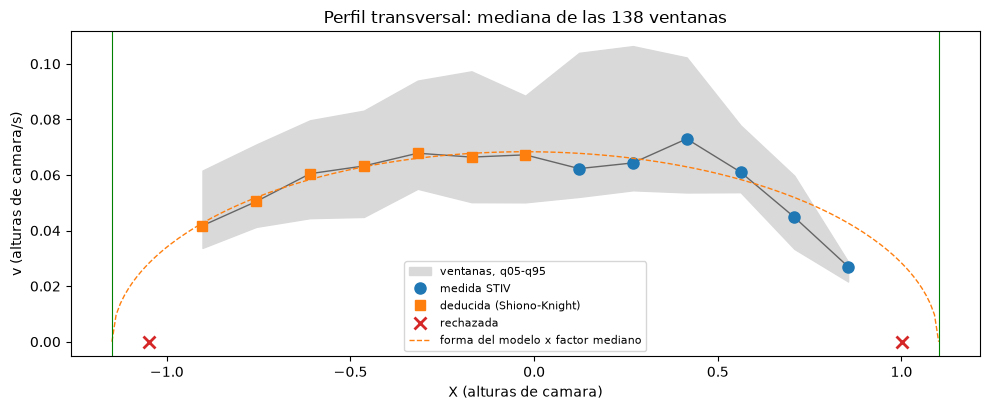

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.2))
q05, q50, q95 = np.nanpercentile(V_u, [5, 50, 95], axis=0)
med_ok = mide.any(axis=0)
ax.fill_between(Xs, q05, q95, color="0.85", label="ventanas, q05-q95")
ax.plot(Xs, q50, "-", color="0.4", lw=1)
ax.plot(Xs[med_ok], q50[med_ok], "o", color="C0", ms=8, label="medida STIV")
ax.plot(Xs[rellenar], q50[rellenar], "s", color="C1", ms=7, label="deducida (Shiono-Knight)")
ax.plot(Xs[~sobre_agua], np.zeros((~sobre_agua).sum()), "x", color="C3", ms=9, mew=2,
        label="rechazada")
xx = np.linspace(geo.X_izq, geo.X_der, 200)
ax.plot(xx, np.median(f_esc) * skm(xx, EJE, GAMMA, 1.0, SEMI) / skm(Xs, EJE, GAMMA, 1.0, SEMI).max(),
        "--", color="C1", lw=1, label="forma del modelo x factor mediano")
ax.axvline(geo.X_izq, color="g", lw=0.8); ax.axvline(geo.X_der, color="g", lw=0.8)
ax.set_xlabel("X (alturas de camara)"); ax.set_ylabel("v (alturas de camara/s)")
ax.set_title("Perfil transversal: mediana de las 138 ventanas")
ax.legend(fontsize=8, loc="lower center")
plt.tight_layout()
plt.savefig(os.path.join(DIR_SALIDAS, "fig5_perfil.png"), dpi=110, bbox_inches="tight")
plt.show()

## 8. Escala metrica y velocidades en m/s

Todo lo anterior esta en **alturas de camara por segundo**. Pasar a metros exige una longitud real,
y este video no tiene ninguna. Se **supone** un ancho de lamina de `ANCHO_LAMINA_M` = 5 m: como el
canal mide `geo.ancho` = 2.25 alturas de camara, la camara queda a ~2.2 m sobre el agua, coherente
con un movil sostenido desde la pasarela que se ve al pie del encuadre.

Es una multiplicacion: el dia que se mida el ancho real basta con cambiar `ANCHO_LAMINA_M` y volver
a ejecutar. Medirlo ademas elimina la dependencia de `FOCAL`, porque fija la escala directamente.

escala supuesta: 2.222 m por altura de camara (lamina de 5.0 m)
v superficial mediana de la seccion: 0.138 m/s (q05-q95 0.105 - 0.178)
solo estaciones medidas: 0.133 m/s


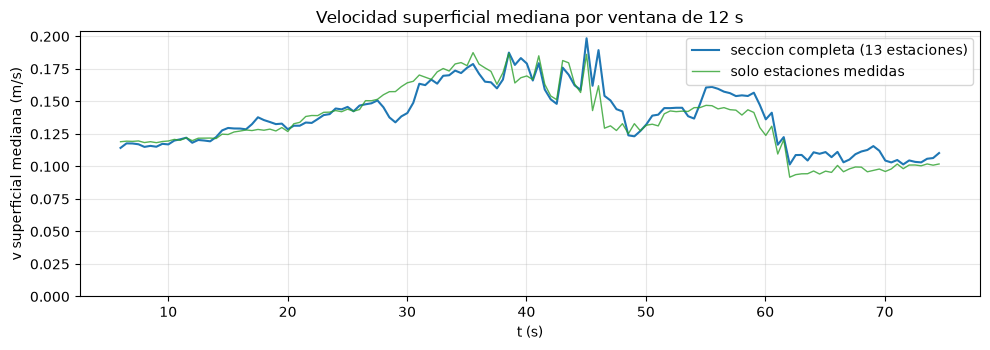

In [13]:
M_POR_U = ANCHO_LAMINA_M / geo.ancho
V = V_u * M_POR_U                                   # m/s, (ventanas x estaciones)
v_mediana = np.nanmedian(V, axis=1)
n_acept = np.isfinite(V).sum(axis=1)
print("escala supuesta: %.3f m por altura de camara (lamina de %.1f m)" % (M_POR_U, ANCHO_LAMINA_M))
print("v superficial mediana de la seccion: %.3f m/s (q05-q95 %.3f - %.3f)"
      % (np.median(v_mediana), np.quantile(v_mediana, 0.05), np.quantile(v_mediana, 0.95)))
print("solo estaciones medidas: %.3f m/s" % (np.nanmedian(med_vent) * M_POR_U))

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(centros / FPS, v_mediana, color="C0", label="seccion completa (%d estaciones)"
        % sobre_agua.sum())
ax.plot(centros / FPS, med_vent * M_POR_U, color="C2", lw=1, alpha=0.8,
        label="solo estaciones medidas")
ax.set_xlabel("t (s)"); ax.set_ylabel("v superficial mediana (m/s)")
ax.set_ylim(0, None); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Velocidad superficial mediana por ventana de 12 s")
plt.tight_layout()
plt.savefig(os.path.join(DIR_SALIDAS, "fig6_serie.png"), dpi=110, bbox_inches="tight")
plt.show()

## 9. El video

Formato del video del rio Bradano (`casos/06_bradano_stiv/salidas/velocidad_tiempo_real.mp4`):
cabecera con titulo y parametros, flechas de color con su valor en m/s, cuadros rojos en las
rechazadas, pie con tiempo, mediana de la seccion y estaciones, y barra de color. Con dos vistas
**a color**:

- **izquierda, la camara original**: las lineas de busqueda y las flechas proyectadas con la
  homografia y con la afinidad de estabilizacion de cada fotograma, asi que siguen al canal aunque
  el movil se mueva;
- **derecha, el plano del agua rectificado**: la vista cenital equivalente a la del Bradano. Los
  triangulos negros de las esquinas son lo que cae fuera del encuadre del movil.

Las dos flechas de cada estacion son la misma: un recorrido en el suelo de largo proporcional a la
velocidad, que la perspectiva acorta en la vista de la camara. Un fotograma de salida por fotograma
de entrada, a los fps originales: el video va a la velocidad real del agua. Cada fotograma usa la
ventana cuyo centro le queda mas cerca.

In [14]:
class EscritorH264:
    # Fotogramas BGR a ffmpeg/libx264 por una tuberia (cv2.VideoWriter solo escribe mp4v aqui)

    def __init__(self, ruta, fps, tam, crf=20):
        self.w, self.h = tam
        cmd = [FFMPEG, "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "bgr24",
               "-s", "%dx%d" % (self.w, self.h), "-r", "%.6f" % fps, "-i", "pipe:0", "-an",
               "-c:v", "libx264", "-preset", "medium", "-crf", str(crf), "-pix_fmt", "yuv420p",
               "-movflags", "+faststart", ruta]
        self.p = subprocess.Popen(cmd, stdin=subprocess.PIPE)

    def write(self, fr):
        self.p.stdin.write(np.ascontiguousarray(fr).tobytes())

    def release(self):
        self.p.stdin.close()
        self.p.wait()


def abrir_escritor(ruta, fps, tam):
    if FFMPEG:
        return EscritorH264(ruta, fps, tam)
    print("AVISO: sin ffmpeg; se escribe mp4v, que no se ve en el navegador")
    return cv2.VideoWriter(ruta, cv2.VideoWriter_fourcc(*"mp4v"), fps, tam)


PALETA = cv2.applyColorMap(np.arange(256, dtype=np.uint8).reshape(-1, 1),
                           cv2.COLORMAP_TURBO).reshape(-1, 3)


def color_velocidad(v):
    if not np.isfinite(v):
        return (120, 120, 120)
    return tuple(int(x) for x in PALETA[int(np.clip(v / V_COLOR_MAX, 0, 1) * 255)])


def texto(img, s, org, escala=0.5, col=(255, 255, 255), grosor=1):
    # Reborde negro: sobre el agua el texto blanco solo no se lee
    cv2.putText(img, s, org, cv2.FONT_HERSHEY_SIMPLEX, escala, (0, 0, 0), grosor + 2, cv2.LINE_AA)
    cv2.putText(img, s, org, cv2.FONT_HERSHEY_SIMPLEX, escala, col, grosor, cv2.LINE_AA)


def pt(p):
    return (int(round(p[0])), int(round(p[1])))


# Disposicion: camara a la izquierda a la altura del panel, rectificado a la derecha
ESC_CAM = ALTO_PANEL / H_IMG
W_CAM = int(round(W_IMG * ESC_CAM))
W_RECT = ANCHO_LIENZO - W_CAM - HUECO
Y_SEC = 0.5 * (Y_MIN + Y_MAX)                       # fila de las flechas: centro del tramo medido
semi_x, semi_y = 0.5 * W_RECT / ESCALA_RECT, 0.5 * ALTO_PANEL / ESCALA_RECT
rst = dict(X0=EJE - semi_x, X1=EJE + semi_x, Y0=Y_SEC - semi_y, Y1=Y_SEC + semi_y,
           w=W_RECT, h=ALTO_PANEL)
mp_pts = np.ascontiguousarray(geo.mapa_rect(rst).reshape(-1, 2))
ALTO_LIENZO = ALTO_CABECERA + ALTO_PANEL + ALTO_PIE
MM_PX = M_POR_U / ESCALA_RECT * 1000.0
L_FLECHA_U = PX_POR_MS / ESCALA_RECT                # alturas de camara de flecha por cada m/s

# Geometria fija del panel rectificado
col_r = geo.rect_a_pix(rst, np.column_stack([Xs, np.full(N_ESTACIONES, Y_SEC)]))[:, 0]
yf_r = int(round(geo.rect_a_pix(rst, [[EJE, Y_SEC]])[0, 1]))
yl0 = int(round(geo.rect_a_pix(rst, [[EJE, Y_MAX]])[0, 1]))
yl1 = int(round(geo.rect_a_pix(rst, [[EJE, Y_MIN]])[0, 1]))
orillas_r = [int(round(geo.rect_a_pix(rst, [[X, Y_SEC]])[0, 0])) for X in (geo.X_izq, geo.X_der)]
# Lo mismo en el suelo, para proyectarlo a la camara en cada fotograma
lineas_suelo = [np.column_stack([np.full(20, X), np.linspace(Y_MIN, Y_MAX, 20)]) for X in Xs]
orillas_suelo = [np.column_stack([np.full(30, X), np.linspace(1.15, 6.0, 30)])
                 for X in (geo.X_izq, geo.X_der)]


def a_camara(P, A):
    # Suelo -> pixel del panel de camara en el fotograma actual
    q = geo.a_imagen(P)
    return (q @ A[:, :2].T + A[:, 2]) * ESC_CAM


lo = hi = None
n_render = NF if FRAMES_VIDEO is None else min(FRAMES_VIDEO, NF)
ruta_video = os.path.join(DIR_SALIDAS, "velocidad_tiempo_real.mp4")
vw = abrir_escritor(ruta_video, FPS, (ANCHO_LIENZO, ALTO_LIENZO))
cap = cv2.VideoCapture(ARCHIVO_VIDEO)
t0 = time.time()
for k in range(n_render):
    ok, fr = cap.read()
    if not ok:
        break
    A = afines[k]
    if lo is None:
        # Percentiles fijos, del primer fotograma: recalcularlos haria parpadear el fondo
        lo, hi = np.percentile(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY), PCT_REALCE)
    realce = np.clip((fr.astype(np.float32) - lo) * (255.0 / (hi - lo)), 0, 255).astype(np.uint8)

    cam = cv2.resize(realce, (W_CAM, ALTO_PANEL), interpolation=cv2.INTER_LINEAR)
    qq = mp_pts @ A[:, :2].T + A[:, 2]
    rect = cv2.remap(realce, qq[:, 0].reshape(ALTO_PANEL, W_RECT).astype(np.float32),
                     qq[:, 1].reshape(ALTO_PANEL, W_RECT).astype(np.float32), cv2.INTER_CUBIC,
                     borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

    w = int(np.argmin(np.abs(centros - k)))
    for P in orillas_suelo:
        cv2.polylines(cam, [np.int32(a_camara(P, A))], False, (60, 200, 60), 1, cv2.LINE_AA)
    for c in orillas_r:
        cv2.line(rect, (c, 0), (c, ALTO_PANEL - 1), (60, 200, 60), 1, cv2.LINE_AA)

    for i in range(N_ESTACIONES):
        v = V[w, i]
        col = color_velocidad(v)
        col_l = col if np.isfinite(v) else (90, 90, 90)
        c = int(round(col_r[i]))
        # Panel de la camara
        cv2.polylines(cam, [np.int32(a_camara(lineas_suelo[i], A))], False, col_l, 1, cv2.LINE_AA)
        b0 = a_camara([[Xs[i], Y_SEC]], A)[0]
        if np.isfinite(v):
            b1 = a_camara([[Xs[i], Y_SEC + v * L_FLECHA_U]], A)[0]
            cv2.arrowedLine(cam, pt(b0), pt(b1), col, 3, cv2.LINE_AA, tipLength=0.25)
            cv2.circle(cam, pt(b0), 4, (255, 255, 255), -1, cv2.LINE_AA)
            cv2.circle(cam, pt(b0), 4, (0, 0, 0), 1, cv2.LINE_AA)
        else:
            cv2.drawMarker(cam, pt(b0), (60, 60, 220), cv2.MARKER_SQUARE, 9, 2)
        # Panel rectificado
        cv2.line(rect, (c, yl0), (c, yl1), col_l, 1, cv2.LINE_AA)
        if np.isfinite(v):
            cv2.arrowedLine(rect, (c, yf_r), (c, int(yf_r - v * PX_POR_MS)), col, 3,
                            cv2.LINE_AA, tipLength=0.18)
            cv2.circle(rect, (c, yf_r), 5, (255, 255, 255), -1, cv2.LINE_AA)
            cv2.circle(rect, (c, yf_r), 5, (0, 0, 0), 1, cv2.LINE_AA)
            texto(rect, "%.2f" % v, (c + 6, yf_r + 24), 0.45, (255, 255, 255), 1)
        else:
            cv2.drawMarker(rect, (c, yf_r), (60, 60, 220), cv2.MARKER_SQUARE, 11, 2)
        texto(rect, "%d" % i, (c - 5 - 5 * (i >= 10), yf_r + 56), 0.45, (230, 230, 230), 1)

    lienzo = np.zeros((ALTO_LIENZO, ANCHO_LIENZO, 3), np.uint8)
    lienzo[ALTO_CABECERA:ALTO_CABECERA + ALTO_PANEL, :W_CAM] = cam
    lienzo[ALTO_CABECERA:ALTO_CABECERA + ALTO_PANEL, W_CAM + HUECO:] = rect
    texto(lienzo, "vista de la camara", (10, ALTO_CABECERA + 22), 0.5, (235, 235, 235), 1)
    texto(lienzo, "plano del agua rectificado", (W_CAM + HUECO + 10, ALTO_CABECERA + 22), 0.5,
          (170, 255, 190), 1)

    texto(lienzo, "Canal piloto Yaqui - STIV en ventana movil sobre el video completo",
          (16, 30), 0.72, (255, 255, 255), 2)
    cab = "ventana %.2f s   escala %.1f mm/px   banda %.0f px   contraste realzado" % (
        VENTANA / FPS, MM_PX, BANDA * ESCALA_RECT)
    tw = cv2.getTextSize(cab, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)[0][0]
    texto(lienzo, cab, (ANCHO_LIENZO - tw - 16, 30), 0.55, (170, 170, 170), 1)

    bx, by, bw_, bh_ = ANCHO_LIENZO - 400, ALTO_LIENZO - 34, 260, 14
    for j in range(bw_):
        cv2.line(lienzo, (bx + j, by), (bx + j, by + bh_),
                 tuple(int(x) for x in PALETA[int(255 * j / (bw_ - 1))]), 1)
    cv2.rectangle(lienzo, (bx, by), (bx + bw_, by + bh_), (90, 90, 90), 1)
    texto(lienzo, "0", (bx - 14, by + 12), 0.45, (170, 170, 170), 1)
    texto(lienzo, "%.1f m/s" % V_COLOR_MAX, (bx + bw_ + 8, by + 12), 0.45, (170, 170, 170), 1)

    y_pie = ALTO_CABECERA + ALTO_PANEL
    texto(lienzo, "t = %5.2f s" % (k / FPS), (16, y_pie + 32), 0.7, (255, 255, 255), 2)
    texto(lienzo, "v superficial mediana = %.3f m/s" % v_mediana[w], (210, y_pie + 32), 0.7,
          (120, 220, 255), 2)
    texto(lienzo, "estaciones medidas = %d/%d" % (n_acept[w], N_ESTACIONES), (700, y_pie + 32),
          0.7, (150, 255, 150), 2)
    texto(lienzo, "circulo = estacion medida   cuadro rojo = rechazada (coherencia baja o cota "
                  "fisica)", (16, y_pie + 62), 0.48, (170, 170, 170), 1)
    texto(lienzo, "la direccion de las flechas no se mide: es el eje del canal que STIV recibe "
                  "como configuracion. El sentido si sale del tensor",
          (16, y_pie + 84), 0.48, (140, 140, 140), 1)
    vw.write(lienzo)
    if (k + 1) % 500 == 0:
        print("  %d/%d fotogramas (%.0f s)" % (k + 1, n_render, time.time() - t0))
cap.release()
vw.release()
print("escrito %s: %dx%d, %d fotogramas (%.1f s), %.1f MB, en %.0f s"
      % (ruta_video, ANCHO_LIENZO, ALTO_LIENZO, n_render, n_render / FPS,
         os.path.getsize(ruta_video) / 1e6, time.time() - t0))

  500/2429 fotogramas (33 s)


  1000/2429 fotogramas (67 s)


  1500/2429 fotogramas (101 s)


  2000/2429 fotogramas (137 s)


escrito salidas\velocidad_tiempo_real.mp4: 1920x770, 2429 fotogramas (81.0 s), 25.4 MB, en 166 s


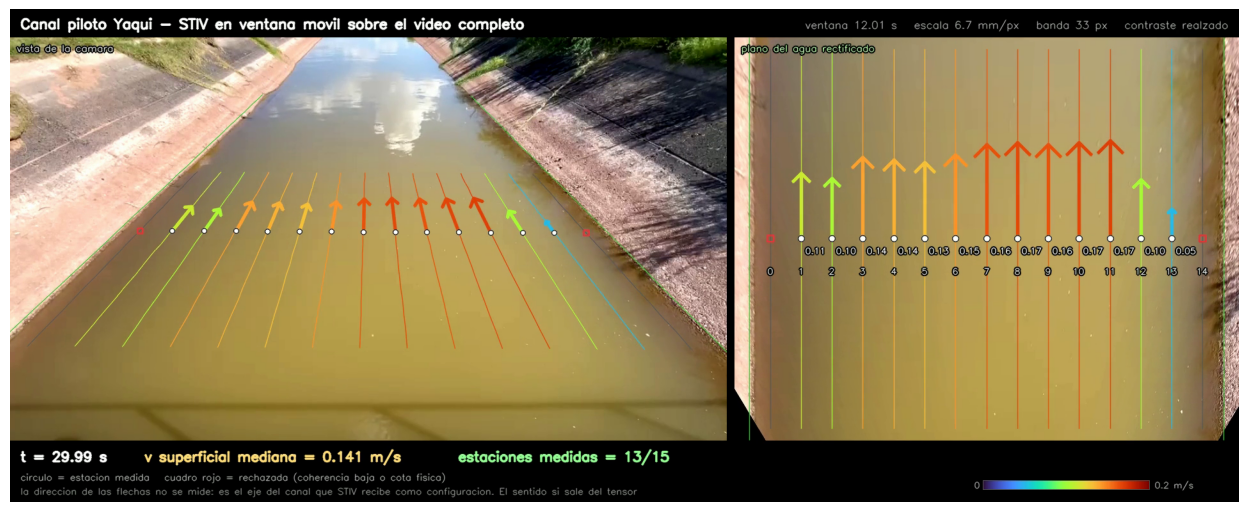

In [15]:
# Un fotograma del video escrito, a los 30 s
cap = cv2.VideoCapture(ruta_video)
cap.set(cv2.CAP_PROP_POS_FRAMES, min(int(30 * FPS), n_render - 1))
ok, muestra = cap.read()
cap.release()
cv2.imwrite(os.path.join(DIR_SALIDAS, "fig7_fotograma_video.png"), muestra)
plt.figure(figsize=(16, 6.4))
plt.imshow(cv2.cvtColor(muestra, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## 10. CSV y configuracion

- `velocidad_ventanas.csv`: una fila por ventana, con el mismo formato que el del Bradano
  (`v_est0` ... `v_est14` en m/s) mas una columna por estacion que dice si ese valor es medida
  directa (`med_est*` = 1) o deducido (0).
- `config.json`: todos los parametros, la geometria, la escala supuesta y que estaciones son
  medidas, deducidas o rechazadas.

In [16]:
with open(os.path.join(DIR_SALIDAS, "velocidad_ventanas.csv"), "w", newline="",
          encoding="utf-8") as fh:
    esc = csv.writer(fh)
    esc.writerow(["ventana", "frame_centro", "t_s", "v_mediana_ms", "n_estaciones"]
                 + ["v_est%d" % i for i in range(N_ESTACIONES)]
                 + ["med_est%d" % i for i in range(N_ESTACIONES)])
    for k, kc in enumerate(centros):
        esc.writerow([k, int(kc), round(kc / FPS, 3), round(float(v_mediana[k]), 4), int(n_acept[k])]
                     + ["" if not np.isfinite(V[k, i]) else round(float(V[k, i]), 4)
                        for i in range(N_ESTACIONES)]
                     + [int(mide[k, i]) for i in range(N_ESTACIONES)])

config = dict(
    video=os.path.relpath(ARCHIVO_VIDEO, RAIZ), n_frames=NF, fps=FPS,
    geometria=dict(focal=FOCAL, orilla_izq=[geo.al, geo.bl], orilla_der=[geo.ar, geo.br],
                   punto_fuga=[geo.xv, geo.yv], inclinacion_grados=float(np.degrees(geo.inclinacion)),
                   ancho_canal_alturas_camara=geo.ancho, X_izq=geo.X_izq, X_der=geo.X_der,
                   estaciones_X=[float(x) for x in Xs]),
    stiv=dict(v_esperada=V_ESPERADA, Y_min=Y_MIN, Y_max=Y_MAX, banda=BANDA, n_lineas=N_LINEAS,
              DS=DS, n_muestras=N_MUES, lado_bloque=LADO_BLOQUE, solape=SOLAPE,
              sigma_tensor=SIGMA_TENSOR, cuantil_senal=CUANTIL_SENAL, coh_min=COH_MIN,
              densidad_min=DENSIDAD_MIN, densidad_max=DENSIDAD_MAX,
              umbral_particula=UMBRAL_PARTICULA, v_max_fisica=V_MAX_FISICA,
              ventana=VENTANA, paso=PASO, n_ventanas=NK),
    medida_81s=[dict(estacion=m["estacion"], X=m["X"], densidad=m["densidad"],
                     coherencia=m["coherencia"],
                     v_alturas_camara_s=None if not np.isfinite(m["v"]) else m["v"],
                     motivos=m["motivos"]) for m in medida_total],
    estaciones_medidas=np.where(mide.any(axis=0))[0].tolist(),
    estaciones_deducidas=np.where(rellenar)[0].tolist(),
    estaciones_rechazadas=np.where(~sobre_agua)[0].tolist(),
    modelo_seccion=dict(tipo="Shiono-Knight, pared en las orillas detectadas", Gamma=GAMMA,
                        eje=EJE, semiancho=SEMI, sigma_bamboleo=sig, autocorrelacion=r_t,
                        recorte=list(lim), semilla=SEMILLA),
    escala=dict(ANCHO_LAMINA_M_SUPUESTO=ANCHO_LAMINA_M, m_por_altura_camara=M_POR_U,
                mm_por_px_panel_rectificado=MM_PX),
    resultado=dict(v_mediana_seccion_ms=float(np.median(v_mediana)),
                   q05=float(np.quantile(v_mediana, 0.05)), q95=float(np.quantile(v_mediana, 0.95)),
                   v_mediana_solo_medidas_ms=float(np.nanmedian(med_vent) * M_POR_U),
                   v_mediana_81s_alturas_camara_s=float(np.median([m["v"] for m in acept]))),
    video_salida=dict(ruta="salidas/velocidad_tiempo_real.mp4", ancho=ANCHO_LIENZO,
                      alto=ALTO_LIENZO, escala_rect=ESCALA_RECT, v_color_max=V_COLOR_MAX,
                      px_por_ms=PX_POR_MS),
)
with open(os.path.join(DIR_SALIDAS, "config.json"), "w", encoding="utf-8") as fh:
    json.dump(config, fh, indent=2, ensure_ascii=False)
print("escritos: salidas/velocidad_ventanas.csv, salidas/config.json")

escritos: salidas/velocidad_ventanas.csv, salidas/config.json


## Limitaciones conocidas

1. **Los m/s dependen de un ancho supuesto** (5 m). Si el canal mide 4 m, todas las velocidades bajan
   un 20 %. Una cinta metrica lo resuelve, y de paso elimina la dependencia de `FOCAL`.
2. **`FOCAL` no se puede medir**: entre 700 y 900 px la velocidad cambia +-9 %. Es un sesgo
   sistematico, no dispersion; mas video o mejor algoritmo no lo reducen.
3. **Solo se mide el tercio derecho del canal** (6 de 15 estaciones). Las 7 de la izquierda son
   modelo: forma de Shiono-Knight y amplitud de las medidas. El modelo es simetrico por construccion,
   asi que pone el maximo en el eje, cuando el maximo medido esta en X ~ +0.4.
4. **Nada valida la magnitud.** No hay aforo ni velocidades de campo. En la version anterior del caso
   (`archivo/08_canal_piloto_yaqui/medicion/`) un rastreo de particulas independiente (PTV) da
   r = +0.984 con STIV pero un 13 % mas bajo; eso comprueba la coherencia interna, no la velocidad
   real del agua.
5. **Los valores estacion por estacion son blandos**: un segundo estimador (cresta del espectro)
   discrepa hasta un tercio en estaciones sueltas aunque coincide al 2 % en la mediana de la seccion.
6. **Sin batimetria no hay caudal.**
7. **Roll nulo y sin correccion de distorsion de lente**: hipotesis, comprobadas solo a ojo (las
   estelas salen rectas y el canal sale recto en el plano rectificado).